In [61]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
#from langchain_community.document_loaders import PyPDFLoader 
# # for image + table+ text kind of. data use --> unstructured.io libraries
from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
#from langchain_community.vectorstores import Chroma
from langchain_chroma import Chroma
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from pydantic import BaseModel
load_dotenv()

True

In [62]:
# pip install tavily

In [63]:
from langgraph.prebuilt import ToolNode
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from typing import Annotated, operator
from langchain_core.tools import tool
from tavily import TavilyClient

In [64]:
# step 1 load the document:
pdf_reader = PdfReader("./documents/evs_oil_price_shock.pdf")

text = ""
for page in pdf_reader.pages:
    text += page.extract_text() + "\n"

print(text[:500])


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
docs = [Document(page_content=text)]

chunks = text_splitter.split_documents(docs)

print(len(chunks))

Will EVs Dampen the Oil Price
 Shock?
Electric Vehicles, Oil Demand Destruction, and the Future of Energy Price
 Volatility
 Version 1.0   |   April 2026
 Technical Reference Document

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 2
Table of Contents
3
Executive Summary
 4
1. Introduction
  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  . 4
1.1 Scope and Methodology
 5
2. Oil 
51


In [65]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
    # persist_directory="../chroma_db". # this is optional for this run
)

vectorstore.add_documents(chunks)

['1ca2c44f-e7a6-42af-a18a-e9ae3bce5b04',
 '9997d281-9e39-4a75-818f-2d98acdc2017',
 'be04909d-ef72-4aea-ae1b-fc6c71741833',
 'd6d3f785-b68d-48b9-95e9-92c61cf08743',
 '402bf325-b7fb-4309-81e5-b4e7edd4e065',
 '433da0d7-f7d9-4629-bc1e-f16229b57807',
 '9f08bef7-9a42-4b66-9ce9-09dcdbb352b0',
 '9161c8e1-0fe6-450f-86e4-b58a9b72890f',
 '9145e506-8fe2-4d1e-ab19-ba5d0c41d8d8',
 '376c2f6a-f1f9-4bd5-96c0-05d22bb208f3',
 '344fcbfc-97dc-475f-8d8f-f7089b50de54',
 '494541aa-f824-4787-832b-cf3dff754c1b',
 '9c711f48-f9ae-4b90-9ff3-8bda704539b7',
 '5a3add4e-d51b-467c-a837-1ee0b2e329f6',
 '473ef965-7470-4f5c-b3f9-0755d6746d6b',
 '4d9a6e73-61a6-43db-bf02-919a3ca432fc',
 '1ce3d115-f5e1-493e-83b6-ab9af7459f7c',
 '7e51ee67-22a9-4583-b8b9-88438b6387ae',
 'c0a63359-9033-46c0-a9ad-809b64af9926',
 '921bd4f7-cf94-4639-a45a-96f08f095663',
 '98100188-adad-4298-863c-b391ca082667',
 'b1ef8c0d-0058-45be-9671-052a1328a932',
 '83384eb0-cde7-43f3-9213-dce1340287ce',
 '9f9e314a-3fbf-4343-a873-a338ea8e16e2',
 '97ecba7c-fda6-

In [66]:
llm = ChatOpenAI(model="gpt-4o-mini") # this is for route_questions and generation
agent_llm = ChatOpenAI(model="gpt-5-mini") 

In [67]:
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool



class RouteDecision(BaseModel):
    needs_retrieval: bool

In [68]:
# Define the tools
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k:int = 3):
    """ 
    Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages.
    
    """

    retriever = vectorstore.as_retriever(search_kwargs={"k": k})
    docs = retriever.invoke(query)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return context,docs


import os

@tool(response_format="content_and_artifact")
def web_search(query:str, max_results:int = 3):
    """
    Search the web for relevant information.
    Adjust max_results (default 3) to retrieve more or fewer results.
    """
    client = TavilyClient(api_key=os.getenv("TVLY_API_KEY"))
    response = client.search(query, max_results=max_results)
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return content, docs

In [69]:
tools = [web_search, vector_store_search]
agent_llm_with_tools = agent_llm.bind_tools(tools)
tool_node = ToolNode(tools)

In [70]:
# agent_llm.invoke('tell me todays news')

In [71]:
def route_question(state: AgenticRAGState) -> dict:

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [72]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

In [73]:
def agent(state: AgenticRAGState) -> dict:
    messages = state['messages']
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]
        
    response = agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}
    

def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [74]:
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [75]:
from typing import Literal
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

In [76]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "agent")
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)


graph = graph_builder.compile()

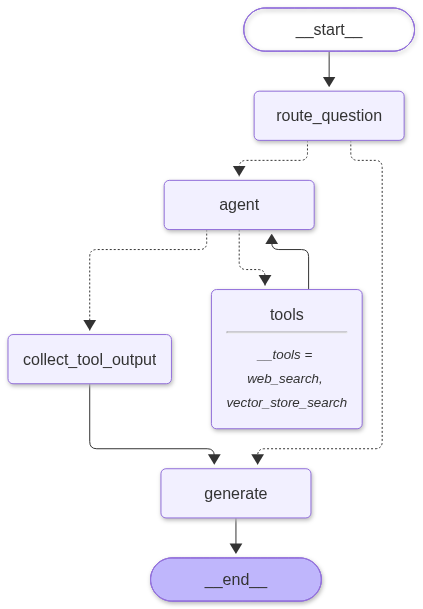

In [77]:
graph

In [79]:
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

In [ ]:
result_vs

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 134, 'prompt_tokens': 438, 'total_tokens': 572, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ElD1KIdIQo3wGb9rRv21ZKFu0OEX6', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1e994-5019-772f-a8ad-7af9c62cce1d-0', tool_calls=[{'name': 'vector_store_search', 'args': {'query': 'Will EVs Dampen the Oil Price Shock? impact of electric vehicle adoption on oil demand EV adoption trajectories oil demand displacement scenarios fleet turnover battery cost trends OPEC+ s

In [80]:
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})


InvalidAPIKeyError: Invalid API key: Unauthorized: missing or invalid API key.

In [ ]:
result_web